# State of the art: the supervisory stress-test models, vine copulas, growth-at-risk and Bayesian VARs

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02, 03 and 07 of this topic (the copulas, the band and the validation tests)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- say what the published state of the art is for the three parts of a capital-and-stress model (the supervisory stress-test models, the scenario generators and the aggregation of risks) and where the case stands against each;
- quantify **model risk** over the set of aggregation models of the band with the two measures of the literature: the add-on multiplier and relative measure of Barrieu and Scandolo (2015), and the worst-case expectation within a relative-entropy budget of Glasserman and Xu (2014);
- recompute the first from the committed band and the second on a simulated aggregate, and read what each says that a single capital figure does not;
- say which of the state-of-the-art tools the engine has (and which of them this notebook ran), which it defers, and why the supervisory models cannot be replicated to a published loss rate here.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the aggregation block of **C18** (Banco Andino), as notebooks 01 to 03 do.

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginals, band, correlation matrix, and the committed `model_risk` block with the Barrieu-Scandolo and Glasserman-Xu results; and `outputs.backcast` for the satellites' out-of-time fit), `data/derived/C18/t-copula-baseline.json` (the Rosenberg and Schuermann reference) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **The marginals are rebuilt from the committed quantile grids, for one step.** The Glasserman-Xu measure needs the simulated losses of the aggregate, which the document does not hold, so step 2 rebuilds the marginals of notebook 02 from the grids and simulates the Gaussian aggregate with the case's seed; the committed numbers are printed beside it.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
print("band rows:", len(band), "| committed model-risk block:", agg["model_risk"]["status"], "| baked by riskvalidation", baseline_doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

derived folder found: True
band rows: 8 | committed model-risk block: information-not-capital | baked by riskvalidation 0.8.1 | installed 0.8.1


## Method

### Step 1: model risk over the set of aggregation models

The band of notebook 03 is a **set of models** for one quantity (the capital): the square-root rule, the Gaussian copula, three t copulas, and the two bounds. A single figure hides the spread among them, and the literature has measures of that spread (Barrieu and Scandolo, 2015). Let $\rho(X_0)$ be the measure under the **reference model**, and $\overline\rho$ and $\underline\rho$ its largest and smallest value over the set $\mathcal L$. Then

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

The **add-on multiplier** AM generalises the Basel multiplier: multiplying the reference capital by $1 + \mathrm{AM}$ reaches the worst case in the set. The **relative measure** RM says where the reference sits between the best and worst case: 0 at the worst, 1 at the best. In the case the reference is the Gaussian copula and the set is the eight rows of the band, as sensitivity **information, not capital**. The next cell recomputes both with `barrieu_scandolo` from the committed capitals, by hand as well, and shows the engine refusing a reference index outside the set.

In [3]:
# Barrieu-Scandolo add-on multiplier and relative measure over the eight band rows, by the engine and by hand
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed = agg["model_risk"]["barrieu_scandolo"]
print("reference model: Gaussian copula, capital", round(measures.rho_x0, 1), "| worst in the set:", round(measures.rho_max, 1), "| best in the set:", round(measures.rho_min, 1))
print("AM (engine):", round(measures.am, 6), "| by hand:", round(max(capitals) / capitals[reference] - 1, 6), "| committed:", round(committed["am"], 6))
print("RM (engine):", round(measures.rm, 6), "| by hand:", round((max(capitals) - capitals[reference]) / (max(capitals) - min(capitals)), 6), "| committed:", round(committed["rm"], 6))
print("multiplying the Gaussian capital by 1 + AM gives", round(measures.rho_x0 * (1 + measures.am), 1), "= the worst case")
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError as err:
    print("a reference index outside the set is refused:", err)

reference model: Gaussian copula, capital 491973.5 | worst in the set: 823331.7 | best in the set: 118517.5
AM (engine): 0.673528 | by hand: 0.673528 | committed: 0.673528
RM (engine): 0.470136 | by hand: 0.470136 | committed: 0.470136
multiplying the Gaussian capital by 1 + AM gives 823331.7 = the worst case
a reference index outside the set is refused: reference_index must lie in [0, 7], got 8


### Step 2: the worst case within an entropy budget

Barrieu and Scandolo's set is the set of models the analyst wrote down. Glasserman and Xu (2014) ask a different question: **how wrong can the reference model be, in a measurable way, before a quantity changes by how much?** Take the baseline law of a loss $V$ (here the aggregate of the Gaussian copula) and consider every alternative law with likelihood ratio $m \ge 0$, $E[m] = 1$, whose **relative entropy** from the baseline is at most a budget $\eta$. The worst expected loss is

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

with $\theta > 0$ chosen so that the entropy constraint binds: the worst case **tilts** the baseline sample towards its large losses, exponentially. It costs only a reweighting of the baseline simulation. `glasserman_xu_worst_case(v, budget)` returns the tilt $\theta$, the entropy reached, the baseline mean and the worst-case mean, and refuses a budget the sample cannot reach (the entropy of a tilt is at most $\log S$).

The case uses the budget $\eta = 0.05$ on the Gaussian aggregate. The next cell rebuilds the marginals of notebook 02 from the committed quantile grids, simulates the aggregate with the case's settings, runs the worst case at four budgets, prints it beside the committed result, and shows the refusal of an unreachable budget.

In [4]:
# Rebuild the marginals from the committed quantile grids, simulate the Gaussian aggregate, then the Glasserman-Xu worst case at four budgets
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("budget of the case:", committed_gx["relative_entropy_budget"], "| committed: baseline", round(committed_gx["baseline_clp_m"], 1), "worst case", round(committed_gx["worst_case_clp_m"], 1), "theta", format(committed_gx["theta"], ".3e"))
print(f'{"budget":>7s} {"theta":>10s} {"entropy":>8s} {"baseline E[V]":>14s} {"worst case":>12s} {"ratio":>6s}')
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    print(f"{budget:7.2f} {gx.theta:10.3e} {gx.relative_entropy:8.4f} {gx.baseline:14,.1f} {gx.worst_case:12,.1f} {gx.worst_case / gx.baseline:6.2f}")
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError as err:
    print("a budget the sample cannot reach is refused:", err)

budget of the case: 0.05 | committed: baseline 66898.5 worst case 143201.8 theta 7.878e-07
 budget      theta  entropy  baseline E[V]   worst case  ratio
   0.01  6.367e-07   0.0100       66,898.7     88,454.2   1.32
   0.05  7.878e-07   0.0500       66,898.7    143,206.7   2.14
   0.10  8.497e-07   0.1000       66,898.7    204,035.3   3.05
   0.20  9.114e-07   0.2000       66,898.7    317,194.7   4.74
a budget the sample cannot reach is refused: budget 10.0 must be below the largest entropy attainable on the sample, log(S / k) = 3.91202 (at most log S = 3.91202)


## State of the art

The persisted research (dossiers 05 and 06) states the practice around each part of the case. The table puts it beside what the case does, with the source and the status of each statement.

| Part | The published practice | In the case and in the engine |
|---|---|---|
| **Supervisory stress-test models** | The Federal Reserve now publishes full model documentation (Fall 2026, credit risk models). Corporate expected loss is $PD \times LGD \times EAD$ per facility; the PD model is a set of 16 OLS regressions of vendor PD on the BBB spread and its four-quarter lag, estimated 2006 to 2023; LGD is stressed through the BBB spread, EAD through a loan-equivalent factor on Shared National Credit data; PPNR has its own 2026 model suite. | Five OLS satellites of charge-off rates by loan type on GDP growth and unemployment, fitted 1985 to 2019 (notebook 04): a simpler, different family. The Federal Reserve models **cannot be replicated to a published loss rate** from the public record, which is why case C19 stays planned (notebook 09). |
| **Bottom-up under constraints** | The EBA 2025 exercise is a constrained bottom-up stress test: banks use their own models under prescribed parameters, with a static balance sheet and benchmark parameters where no adequate satellite exists (Methodological Note, paragraphs 33 to 38 and 122 to 124). | The static rules by paragraph are applied and tested (notebook 05); the case has one bank and no challenger, so bottom-up against top-down is a rule shown, not a comparison made (notebook 07). |
| **Scenario generators** | Bayesian VARs with Minnesota priors (Litterman 1986; Banbura, Giannone and Reichlin 2010), global VARs, growth-at-risk with a skewed-t density (Adrian, Boyarchenko and Giannone 2019) and a panel quantile satellite (Covas, Rump and Zakrajsek 2014). | The engine has the VAR conditional forecast and the skewed-t step of growth-at-risk (notebook 04); the quantile-regression step needs `statsmodels`, absent from this environment; the Minnesota BVAR and the panel quantile satellite are deferred (backlog item BL-078). |
| **Risk aggregation** | Rosenberg and Schuermann (2006): total risk is more sensitive to the business mix than to the inter-risk correlations, the copula choice has a modest effect, and the additive approximation overestimates risk by about 30 to 40 percent. The Joint Forum found aggregation models "a work in progress" on which supervisors generally do not rely (the press release of 21 October 2010, https://www.bis.org/press/p101021.htm, gives both phrases). Vine copulas are available offline in `pyvinecopulib`. | The ladder from the simple sum to the worst case (notebooks 01 to 03), and the reference of Rosenberg and Schuermann read beside the result. The engine has Gaussian and t copulas and the closed forms of Clayton; **vine copulas are not in the engine** (BL-078) and `pyvinecopulib` is not in this environment. |
| **Model-risk quantification** | Barrieu and Scandolo (2015) and Glasserman and Xu (2014), as above; quantitative model-risk measures are sensitivity information, never a regulatory capital figure. | Both are in the engine and run in steps 1 and 2; the case labels them `information-not-capital`. |

The next cell reads the case's own numbers for each row of the table that can be measured on the committed documents: the additive overestimate against the published range, the spread of the band, the model-risk measures, and the back-cast of the satellites.

In [5]:
# Measure on the committed documents what each row of the table can be measured on
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
print("Rosenberg and Schuermann: additive overestimate here", round(simple_sum / gaussian - 1, 4), "| published range", reference["published_additive_overestimate"], "| inside:", reference["within_published_range"])
diversified = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("copula choice, spread of the copula rows over the Gaussian row:", round(max(diversified) / gaussian - 1, 4), "| business mix: capitals", {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in agg["marginals"]})
print("band spread: worst case over lower bound:", round(max(r["capital_clp_m"] for r in band) / min(r["capital_clp_m"] for r in band), 2), "| AM:", round(measures.am, 4), "| RM:", round(measures.rm, 4))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
print("satellites' back-cast peak ratios (predicted over realised):", {b["fed_loan_type"]: round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast})
print("Federal Reserve and EBA models: not replicable here; vine copulas and Bayesian VARs: not in the engine")

Rosenberg and Schuermann: additive overestimate here 0.3376 | published range {'low': 0.3, 'high': 0.4} | inside: True
copula choice, spread of the copula rows over the Gaussian row: 0.1228 | business mix: capitals {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
band spread: worst case over lower bound: 6.95 | AM: 0.6735 | RM: 0.4701
satellites' back-cast peak ratios (predicted over realised): {'commercial-industrial': 4.55, 'commercial-real-estate': 13.14, 'residential': 252.13, 'credit-cards': 4.3, 'other-consumer': 2.09}
Federal Reserve and EBA models: not replicable here; vine copulas and Bayesian VARs: not in the engine


## Results

The figure draws the band as a multiple of the Gaussian reference, with the Barrieu-Scandolo add-on multiplier as the distance to the worst case, and marks the range the published additive overestimate would give for the simple sum.

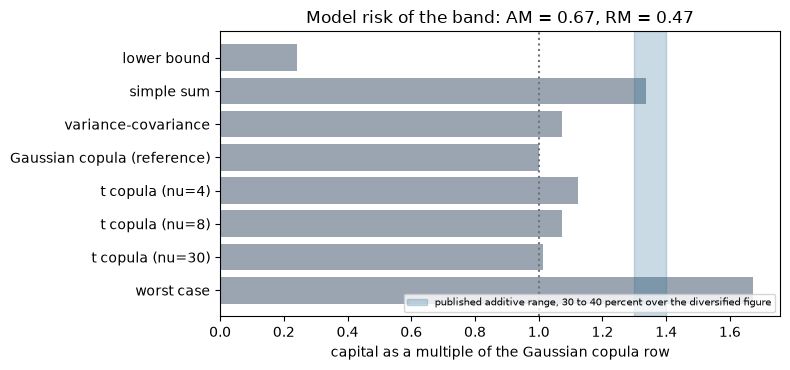

In [6]:
# Draw the band as a multiple of the Gaussian reference, with the published additive range for the simple sum shaded
NAMES = {"lower-bound": "lower bound", "simple-sum": "simple sum", "variance-covariance": "variance-covariance",
         "gaussian-copula": "Gaussian copula (reference)", "t-copula": "t copula", "worst-case": "worst case"}
names = [NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in band]
multiple = [r["capital_clp_m"] / gaussian for r in band]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label="published additive range, 30 to 40 percent over the diversified figure")
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital as a multiple of the Gaussian copula row")
ax.set_title(f"Model risk of the band: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

- **The set of aggregation models is wide.** The Gaussian reference is CLP 491,974 million, and the eight rows of the band run from 118,518 (lower bound) to 823,332 (worst case), a ratio of 6.95. The add-on multiplier is **0.6735**: multiplying the reference by 1.67 reaches the worst case. The relative measure is **0.4701**: the reference sits 47 percent of the way down from the worst case to the best. The engine and the by-hand formulas agree with the committed block to the digit, and a reference index outside the set is refused.
- **The entropy budget turns a modelling doubt into a number.** On the aggregate simulated from the committed marginals, whose baseline mean is 66,899, the worst expected loss within a budget of 0.01, 0.05, 0.10 and 0.20 is 88,454, 143,207, 204,035 and 317,195 (1.32, 2.14, 3.05 and 4.74 times the baseline). At the case's budget of 0.05 it is the committed block: 143,207 against 143,202, with a tilt of 7.878e-7 in both. The worst case grows faster than the budget because the aggregate is heavy-tailed: the more tail the baseline has, the more a given budget can move its mean. A budget the sample cannot reach (entropy above $\log S = 3.91$) is refused.
- **Against the published practice:** the additive overestimate of the case, 33.76 percent, is inside the 30 to 40 percent of Rosenberg and Schuermann; the t copula with $\nu = 4$ is 12.3 percent above the Gaussian one, a larger copula effect than the paper's "modest"; and the satellites' back-cast peak ratios, 2.09 to 252.13, say that the stressed credit loss of the case rests on satellites that fail their own validation (notebook 07).
- **What the case does not have is stated:** the Federal Reserve models cannot be replicated to a published loss rate from the public record, vine copulas and the Minnesota BVAR are not in the engine, and the first step of growth-at-risk needs a package this environment lacks.

What this notebook does not show: the Glasserman-Xu figures are on an aggregate simulated from a grid of 1,961 points per marginal, which agrees with the committed block to 0.01 percent and not to the digit; the table of the state of the art is the research's, with its UNVERIFIED items marked, not a fresh literature review; and no number in it is a regulatory result.

## Summary

- The published practice has three layers: supervisory models (Federal Reserve, EBA), scenario generators (BVAR, GVAR, growth-at-risk, panel quantile) and aggregation (copulas, vines, the Joint Forum's caution); the case implements a simpler satellite family, the EBA static rules, a VAR and skewed-t mechanics, and the Gaussian, t and worst-case ladder.
- Model risk over the band is measured by the add-on multiplier and relative measure of Barrieu and Scandolo, which the engine recomputes exactly from the committed capitals, and by the Glasserman-Xu worst case within an entropy budget, which needs the simulated aggregate and tilts it towards its large losses.
- Both measures are sensitivity information for the validator, labelled `information-not-capital`, and say what one capital figure hides.
- What the engine does not have is stated, not hidden: vine copulas, the Minnesota BVAR, the panel quantile satellite and the first step of growth-at-risk (it needs `statsmodels`); the Federal Reserve models cannot be replicated to a published loss rate from the public record.

**What to try next.** Change the reference model of step 1 to the t copula with $\nu = 4$ and see how the add-on multiplier and relative measure move; then continue with notebook 09, which turns the band into a claim and reads the declared readiness of the case.

## References

- Glasserman, P. and Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. and Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation. https://www.bis.org/publ/joint25.pdf
- Bank for International Settlements (2010), press release of 21 October 2010 on the Joint Forum report Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026. https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note of 2025-01-20: the static balance sheet (paragraphs 24, 33, 34 and 90 to 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. and Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. and Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. and Zakrajsek, E. (2014), the panel quantile satellite, and Pesaran, Schuermann and Weiner (2004), the global VAR, as summarised in dossier 05, H.2 (no link: not read in this repository's research basis).
- This repository: `docs/contracts/engine/aggregation-api.md` (the model-risk functions).